# Celda 0: Preparar entorno

In [ ]:
# recarga los .py de src/ al editarlos, sin reiniciar el kernel
%reload_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Las rutas son relativas, así que solo funcionan desde notebooks/
if not Path("../src/visualization.py").exists():
    raise FileNotFoundError(
        "No se encontró ../src/visualization.py. Solución: abre "
        "este notebook desde la carpeta notebooks/ del proyecto."
    )

import visualization as viz 

sys.path.insert(0, "../src")

PROC = Path("../data/processed")
TABLES = Path("../results/tables")
FIGURES = Path("../results/figures")
FIGURES.mkdir(parents=True, exist_ok=True)


print("Entorno listo")

Entorno listo


# Celda 1: Cargar tabla 

In [ ]:
deg_table = viz.load_results(TABLES / "deg_results_completa.csv")

counts = pd.read_csv(PROC / "counts_filtered.csv", index_col=0)
size_factors = pd.read_csv(TABLES / "factores_de_tamano.csv", index_col=0).squeeze()
meta = pd.read_csv(PROC / "sample_metadata.csv", index_col=0)

counts = counts[meta.index]                       # mismo orden que los metadatos
log_counts = np.log2(counts / size_factors + 1)   # quita profundidad, comprime escala

degs = deg_table[deg_table["regulacion"] != "sin cambio"]

print(f"Genes graficables : {len(deg_table)}")
print(f"Diferenciales     : {len(degs)}")
print(f"Muestras          : {counts.shape[1]}")
print()
print(deg_table["regulacion"].value_counts().to_string())
plt.show()

Genes graficables : 4967
Diferenciales     : 1458
Muestras          : 15

regulacion
sin cambio    3509
inducido       830
reprimido      628


# Celda 2: Volcano plot

Guardada en ..\results\figures\volcano_plot.png


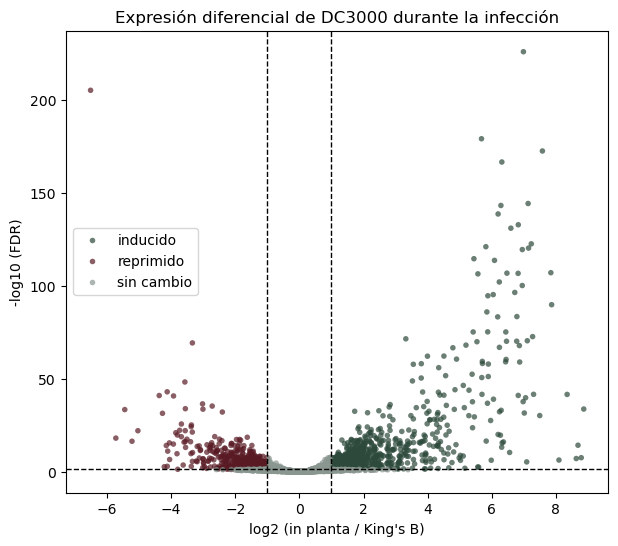

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
viz.plot_volcano(deg_table, ax=ax)

fig.savefig(FIGURES / "volcano_plot.png", dpi=200, bbox_inches="tight")
print(f"Guardada en {FIGURES / 'volcano_plot.png'}")